# Neural networks for image classification

A NumPy classifier on two interlocking moons makes the effects of learning rate and hidden width visible. The second experiment compares a linear pixel classifier with a two-layer convolutional network on CIFAR-10. The figures and epoch summaries retained here are from the original runs.

## Backpropagation on two moons

The network uses one ReLU hidden layer and a scalar output. For a label $y$ in $\{-1,1\}$ and output $z$, the logistic loss is $\log(1+\exp(-yz))$. Its derivative with respect to $z$ is $-y\,\sigma(-yz)$. Backpropagation multiplies this derivative by each output weight and the corresponding ReLU mask.

In [ ]:
from pathlib import Path
from urllib.request import urlopen
from shutil import copyfileobj


def fetch_asset(url):
    target = Path("data") / url.rsplit("/", 1)[-1]
    if target.exists():
        return target
    target.parent.mkdir(exist_ok=True)
    temp = target.with_suffix(".part")
    with urlopen(url, timeout=60) as response, temp.open("wb") as output:
        copyfileobj(response, output)
    temp.replace(target)
    return target


from IPython import display
import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio


def decision_boundary_nnet(X, Y, Wi, bi, Wo, bo):
    x_min, x_max = -2, 4
    y_min, y_max = -5, 3
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))

    XX = np.vstack((xx.ravel(), yy.ravel())).T
    input_hidden = np.dot(XX, Wi) + bi
    hidden = np.maximum(input_hidden, 0)
    Z = np.dot(hidden, Wo) + bo

    # Put the result into a color plot
    Z = Z.reshape(xx.shape)
    plt.contourf(xx, yy, Z > 0, cmap=plt.cm.Paired)
    plt.axis("off")

    # Plot also the training points
    plt.scatter(X[:, 0], X[:, 1], c=Y, cmap="winter")
    plt.axis([-2, 4, -5, 3])
    plt.draw()


def sigm(x):
    # Returns the sigmoid of x.
    return np.exp(-np.logaddexp(0, -x))  # = 1 / (1 + exp(-x)), computed without overflow


def nnet_forward_logloss(X, Y, Wi, bi, Wo, bo):
    """
    Compute the output Po, Yo and the loss of the network for the input X
    This is a 2 layer (1 hidden layer network)

    Input:
        X ... (in R^2) set of input points, one per row
        Y ... {-1,1} the target values for the set of points X
        Wi, bi, Wo, bo ... parameters of the network

    Output:
       Po ... probabilisitc output of the network P(class=1 | x)
                  Po is in <0 1>.
                  Note: P(class=-1 | x ) = 1 - Po
       Yo ... output of the network Yo is in <-inf +inf>
       loss ... logistic loss of the network on examples X with ground target
                    values Y in {-1,1}
    """
    # Hidden layer
    hidden = np.maximum(np.dot(X, Wi) + bi, 0)
    # Output of the network
    Yo = np.dot(hidden, Wo) + bo
    # Probabilistic output
    Po = sigm(Yo)
    # Logistic loss
    loss = np.logaddexp(0, -Y * Yo)  # = log(1 + exp(-Y * Yo)), computed without overflow
    return Po, Yo, loss


# Load the training data
fetch_asset("https://www.di.ens.fr/willow/teaching/recvis_orig/assignment2/double_moon_train1000.mat")
train_data = sio.loadmat("data/double_moon_train1000.mat", squeeze_me=True)
Xtr = train_data["X"]
Ytr = train_data["Y"]
# Load the validation data
fetch_asset("https://www.di.ens.fr/willow/teaching/recvis_orig/assignment2/double_moon_val1000.mat")
val_data = sio.loadmat("data/double_moon_val1000.mat", squeeze_me=True)
Xval = val_data["X"]
Yval = val_data["Y"]

In [ ]:
def gradient_nn(X, Y, Wi, bi, Wo, bo):
    """
    Compute gradient of the logistic loss of the neural network on example X with
    target label Y, with respect to the parameters Wi,bi,Wo,bo.

    Input:
        X ... 2d vector of the input example
        Y ... the target label in {-1,1}
        Wi,bi,Wo,bo ... parameters of the network
        Wi ... [dxh]
        bi ... [h]
        Wo ... [h]
        bo ... 1
        where h... is the number of hidden units
              d... is the number of input dimensions (d=2)

    Output:
        grad_s_Wi [dxh] ... gradient of loss s(Y,Y(X)) w.r.t  Wi
        grad_s_bi [h]   ... gradient of loss s(Y,Y(X)) w.r.t. bi
        grad_s_Wo [h]   ... gradient of loss s(Y,Y(X)) w.r.t. Wo
        grad_s_bo 1     ... gradient of loss s(Y,Y(X)) w.r.t. bo
    """

    pre_hidden = X @ Wi + bi
    hidden = np.maximum(pre_hidden, 0.0)
    Yo = hidden @ Wo + bo

    grad_s_Yo = -Y * sigm(-Y * Yo)
    grad_s_pre_hidden = grad_s_Yo * Wo * (pre_hidden > 0)

    grad_s_Wi = np.outer(X, grad_s_pre_hidden)
    grad_s_bi = grad_s_pre_hidden
    grad_s_Wo = grad_s_Yo * hidden
    grad_s_bo = grad_s_Yo

    return grad_s_Wi, grad_s_bi, grad_s_Wo, grad_s_bo

### Numerical gradient check

Central differences perturb each parameter in both directions. On 1,000 random examples the check compares the analytical and numerical gradients for both weights and biases at a tolerance of $10^{-6}$.

In [ ]:
def gradient_nn_numerical(X, Y, Wi, bi, Wo, bo):
    """
    Compute numerical gradient of the logistic loss of the neural network on
    example X with target label Y, with respect to the parameters Wi,bi,Wo,bo.

    Input:
       X ... 2d vector of the input example
       Y ... the target label in {-1,1}
       Wi, bi, Wo, bo ... parameters of the network
       Wi ... [dxh]
       bi ... [h]
       Wo ... [h]
       bo ... 1
       where h... is the number of hidden units
             d... is the number of input dimensions (d=2)

    Output:
       grad_s_Wi_numerical [dxh] ... gradient of loss s(Y,Y(X)) w.r.t  Wi
       grad_s_bi_numerical [h]   ... gradient of loss s(Y,Y(X)) w.r.t. bi
       grad_s_Wo_numerical [h]   ... gradient of loss s(Y,Y(X)) w.r.t. Wo
       grad_s_bo_numerical 1     ... gradient of loss s(Y,Y(X)) w.r.t. bo
    """

    eps = 1e-8
    grad_s_Wi_numerical = np.zeros(Wi.shape)
    grad_s_bi_numerical = np.zeros(bi.shape)
    grad_s_Wo_numerical = np.zeros(Wo.shape)

    for i in range(Wi.shape[0]):
        for j in range(Wi.shape[1]):
            dummy, dummy, pos_loss = nnet_forward_logloss(X, Y, sumelement_matrix(Wi, i, j, +eps), bi, Wo, bo)
            dummy, dummy, neg_loss = nnet_forward_logloss(X, Y, sumelement_matrix(Wi, i, j, -eps), bi, Wo, bo)
            grad_s_Wi_numerical[i, j] = (pos_loss - neg_loss) / (2 * eps)

    for i in range(bi.shape[0]):
        dummy, dummy, pos_loss = nnet_forward_logloss(X, Y, Wi, sumelement_vector(bi, i, +eps), Wo, bo)
        dummy, dummy, neg_loss = nnet_forward_logloss(X, Y, Wi, sumelement_vector(bi, i, -eps), Wo, bo)
        grad_s_bi_numerical[i] = (pos_loss - neg_loss) / (2 * eps)

    for i in range(Wo.shape[0]):
        dummy, dummy, pos_loss = nnet_forward_logloss(X, Y, Wi, bi, sumelement_vector(Wo, i, +eps), bo)
        dummy, dummy, neg_loss = nnet_forward_logloss(X, Y, Wi, bi, sumelement_vector(Wo, i, -eps), bo)
        grad_s_Wo_numerical[i] = (pos_loss - neg_loss) / (2 * eps)

    dummy, dummy, pos_loss = nnet_forward_logloss(X, Y, Wi, bi, Wo, bo + eps)
    dummy, dummy, neg_loss = nnet_forward_logloss(X, Y, Wi, bi, Wo, bo - eps)
    grad_s_bo_numerical = (pos_loss - neg_loss) / (2 * eps)

    return grad_s_Wi_numerical, grad_s_bi_numerical, grad_s_Wo_numerical, grad_s_bo_numerical


def sumelement_matrix(X, i, j, element):
    Y = np.copy(X)
    Y[i, j] = X[i, j] + element
    return Y


def sumelement_vector(X, i, element):
    Y = np.copy(X)
    Y[i] = X[i] + element
    return Y

In [ ]:
def gradcheck():
    """
    Check that the numerical and analytical gradients are the same up to eps
    """
    h = 3  # number of hidden units
    eps = 1e-6
    for i in range(1000):
        # Generate random input/output/weight/bias
        X = np.random.randn(2)
        Y = 2 * np.random.randint(2) - 1  # {-1, 1}
        Wi = np.random.randn(X.shape[0], h)
        bi = np.random.randn(h)
        Wo = np.random.randn(h)
        bo = np.random.randn()
        # Compute analytical gradients
        grad_s_Wi, grad_s_bi, grad_s_Wo, grad_s_bo = gradient_nn(X, Y, Wi, bi, Wo, bo)
        # Compute numerical gradients
        grad_s_Wi_numerical, grad_s_bi_numerical, grad_s_Wo_numerical, grad_s_bo_numerical = gradient_nn_numerical(
            X, Y, Wi, bi, Wo, bo
        )
        # Compute the difference between analytical and numerical gradients
        delta_Wi = np.mean(np.abs(grad_s_Wi - grad_s_Wi_numerical))
        delta_bi = np.mean(np.abs(grad_s_bi - grad_s_bi_numerical))
        delta_Wo = np.mean(np.abs(grad_s_Wo - grad_s_Wo_numerical))
        delta_bo = np.abs(grad_s_bo - grad_s_bo_numerical)
        # Difference larger than a threshold
        if delta_Wi > eps or delta_bi > eps or delta_Wo > eps or delta_bo > eps:
            return False

    return True


# Check gradients
if gradcheck():
    print("SUCCESS: Passed gradcheck.")
else:
    print("Gradient check failed.")

SUCCESS: Passed gradcheck.

### Learning rate and hidden width

The optimizer draws one training point per update. Five runs with seven hidden units and a learning rate of 0.02 show how much the final error varies with initialization and sample order.

In [ ]:
def train_loop(Xtr, Ytr, Xval, Yval, h, lrate, vis="all", nEpochs=100):
    """
    Train the network with SGD and record the training / validation errors after every iteration

    Input:
        Xtr ... Nx2 matrix of training samples
        Ytr ... N dimensional vector of training labels
        Xval ... Nx2 matrix of validation samples
        Yval ... N dimensional vector validation labels
        h ... number of hidden units
        lrate ... learning rate
        vis ... visulaization option ('all' | 'last' | 'never')
        nEpochs ... number of training epochs

    Output:
        tr_error ... nEpochs*nSamples dimensional vector of training error
        val_error ... nEpochs*nSamples dimensional vector of validation error
    """

    nSamples = Xtr.shape[0]
    tr_error = np.zeros(nEpochs * nSamples)
    val_error = np.zeros(nEpochs * nSamples)

    # Randomly initialize parameters of the model
    Wi = np.random.randn(Xtr.shape[1], h)
    Wo = np.zeros(h)
    bi = np.zeros(h)
    bo = 0.0

    if vis == "all" or vis == "last":
        plt.figure()

    for i in range(nEpochs * nSamples):
        # Draw an example at random
        n = np.random.randint(nSamples)
        X = Xtr[n]
        Y = Ytr[n]

        # Compute gradient
        grad_s_Wi, grad_s_bi, grad_s_Wo, grad_s_bo = gradient_nn(X, Y, Wi, bi, Wo, bo)

        # Gradient update
        Wi -= lrate * grad_s_Wi
        Wo -= lrate * grad_s_Wo
        bi -= lrate * grad_s_bi
        bo -= lrate * grad_s_bo

        # Compute training error
        Po, Yo, loss = nnet_forward_logloss(Xtr, Ytr, Wi, bi, Wo, bo)
        Yo_class = np.sign(Yo)
        tr_error[i] = 100 * np.mean(Yo_class != Ytr)

        # Compute validation error
        Pov, Yov, lossv = nnet_forward_logloss(Xval, Yval, Wi, bi, Wo, bo)
        Yov_class = np.sign(Yov)
        val_error[i] = 100 * np.mean(Yov_class != Yval)

        # Plot (at every epoch if visualization is 'all', only at the end if 'last')
        if (vis == "all" and i % nSamples == 0) or (vis == "last" and i == nEpochs * nSamples - 1):
            # Draw the decision boundary.
            plt.clf()
            plt.title("p = %d, Iteration = %.d, Error = %.3f" % (h, i / nSamples, tr_error[i]))
            decision_boundary_nnet(Xtr, Ytr, Wi, bi, Wo, bo)
            display.display(plt.gcf(), display_id=True)
            display.clear_output(wait=True)

    if vis == "all":
        # Plot the evolution of the training and test errors
        plt.figure()
        plt.plot(tr_error, label="training")
        plt.plot(val_error, label="validation")
        plt.legend()
        plt.title("Training/validation errors: %.2f%% / %.2f%%" % (tr_error[-1], val_error[-1]))
    return tr_error, val_error

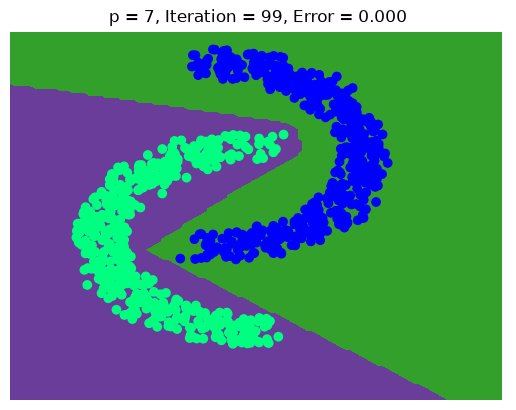

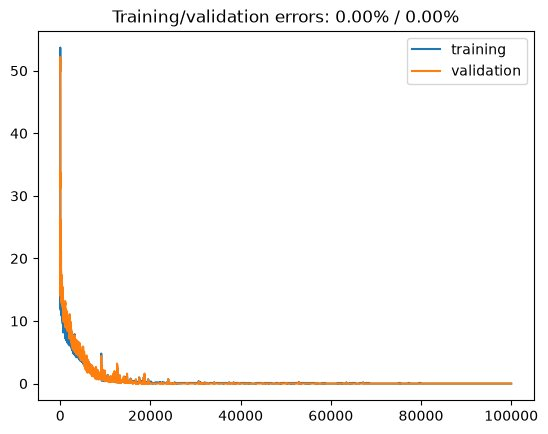

In [ ]:
# Run training
h = 7
lrate = 0.02
tr_error, val_error = train_loop(Xtr, Ytr, Xval, Yval, h, lrate)

In [ ]:
print("Run | Training error (%) | Validation error (%)")

for run in range(1, 6):
    tr_error, val_error = train_loop(
        Xtr, Ytr, Xval, Yval,
        h=7,
        lrate=0.02,
        vis="never",
        nEpochs=10,
    )

    print(f"{run} | {tr_error[-1]:.2f} | {val_error[-1]:.2f}")

Run | Training error (%) | Validation error (%)
1 | 0.80 | 0.80
2 | 1.30 | 1.80
3 | 0.80 | 0.70
4 | 0.50 | 0.60
5 | 0.80 | 0.60

In [ ]:
nEpochs = 40
trials = 5
lrates = [2, 0.2, 0.02, 0.002]
plot_data_lr = np.zeros((2, trials, len(lrates), nEpochs * 1000))
h = 7
for j, lrate in enumerate(lrates):
    print("LR = %f" % lrate)
    for i in range(trials):
        tr_error, val_error = train_loop(Xtr, Ytr, Xval, Yval, h, lrate, vis="never", nEpochs=nEpochs)
        plot_data_lr[0, i, j, :] = tr_error
        plot_data_lr[1, i, j, :] = val_error

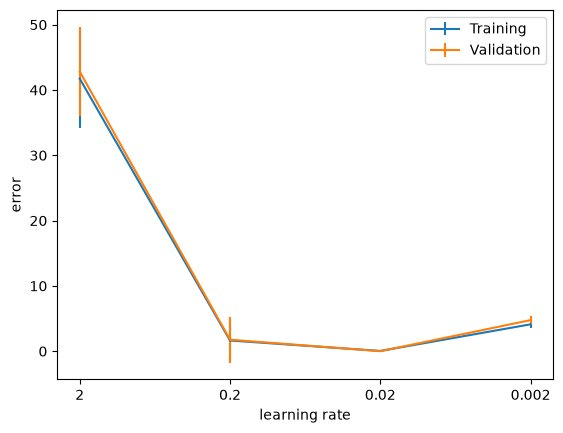

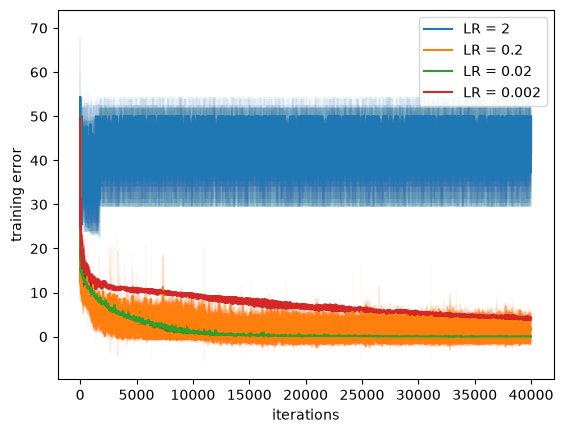

In [ ]:
plt.errorbar(
    np.arange(len(lrates)),
    plot_data_lr[0, :, :, -1].mean(axis=0),
    yerr=plot_data_lr[0, :, :, -1].std(axis=0),
    label="Training",
)
plt.errorbar(
    np.arange(len(lrates)),
    plot_data_lr[1, :, :, -1].mean(axis=0),
    yerr=plot_data_lr[1, :, :, -1].std(axis=0),
    label="Validation",
)
plt.xticks(np.arange(len(lrates)), lrates)
plt.xlabel("learning rate")
plt.ylabel("error")
plt.legend()

# Plot the evolution of the training loss for each learning rate
plt.figure()
for j, lrate in enumerate(lrates):
    x = np.arange(plot_data_lr.shape[3])
    # Mean training loss over trials
    y = plot_data_lr[0, :, j, :].mean(axis=0)
    # Standard deviation over trials
    ebar = plot_data_lr[0, :, j, :].std(axis=0)
    # Plot
    markers, caps, bars = plt.errorbar(x, y, yerr=ebar, label="LR = " + str(lrate))
    # Make the error bars transparent
    [bar.set_alpha(0.01) for bar in bars]
plt.legend()
plt.xlabel("iterations")
plt.ylabel("training error")

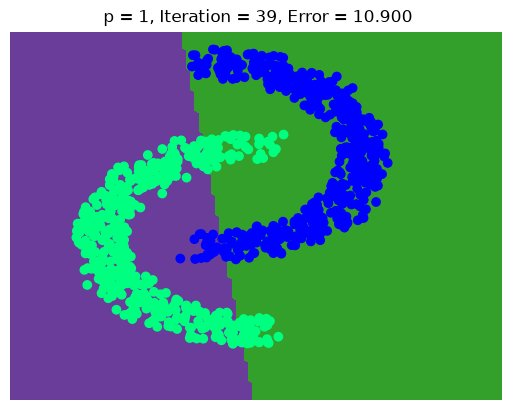

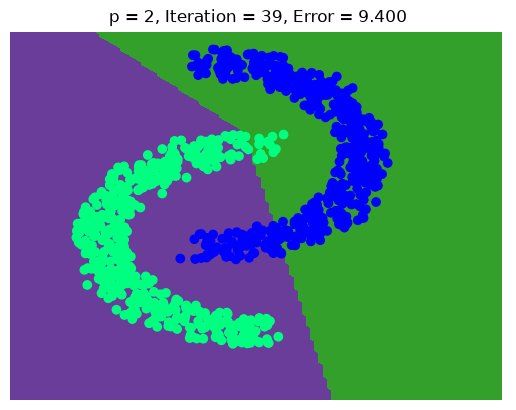

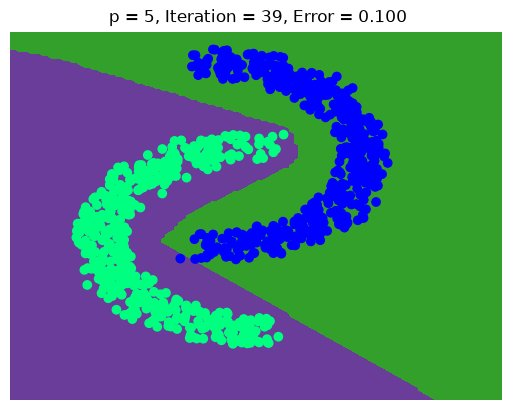

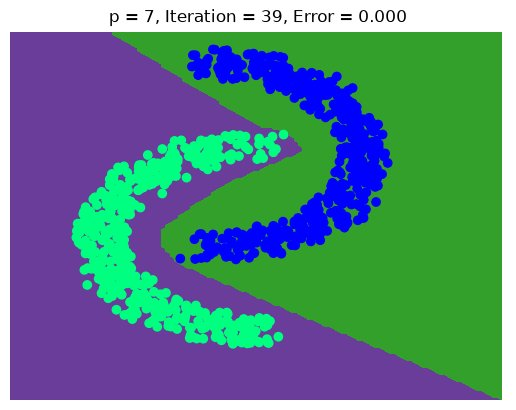

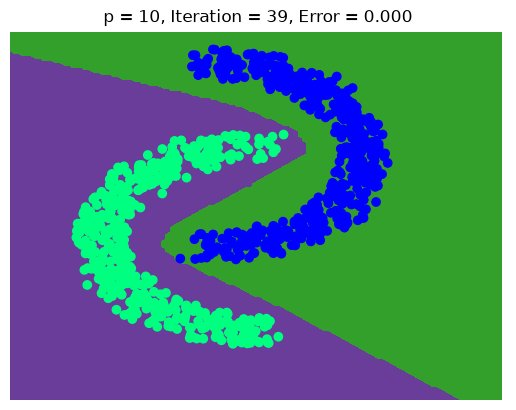

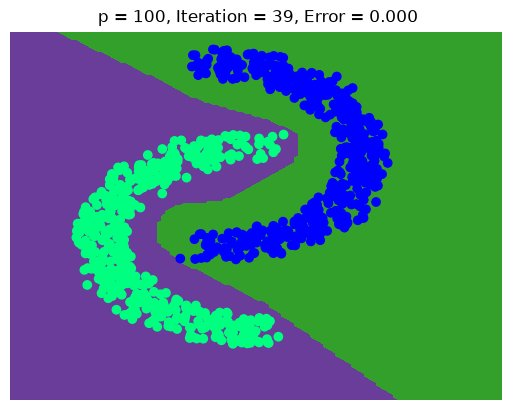

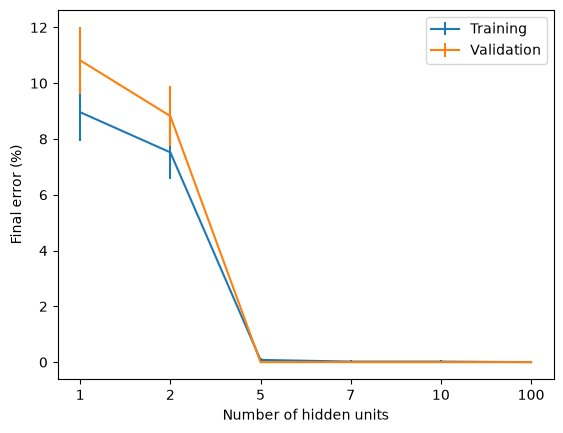

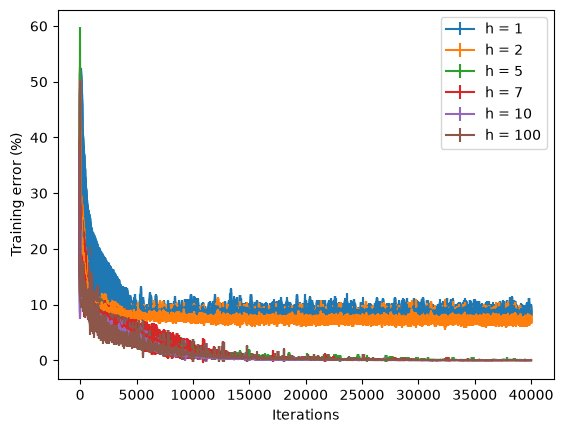

In [ ]:
nEpochs = 40
trials = 5
hidden_units = [1, 2, 5, 7, 10, 100]
lrate = 0.02
n_iterations = nEpochs * Xtr.shape[0]

plot_data_h = np.zeros((2, trials, len(hidden_units), n_iterations))

for j, h in enumerate(hidden_units):
    for i in range(trials):
        tr_error, val_error = train_loop(
            Xtr, Ytr, Xval, Yval,
            h=h,
            lrate=lrate,
            vis="last" if i == 0 else "never",
            nEpochs=nEpochs,
        )
        plot_data_h[0, i, j, :] = tr_error
        plot_data_h[1, i, j, :] = val_error

plt.show()

x = np.arange(len(hidden_units))

plt.figure()
plt.errorbar(
    x,
    plot_data_h[0, :, :, -1].mean(axis=0),
    yerr=plot_data_h[0, :, :, -1].std(axis=0),
    label="Training",
)
plt.errorbar(
    x,
    plot_data_h[1, :, :, -1].mean(axis=0),
    yerr=plot_data_h[1, :, :, -1].std(axis=0),
    label="Validation",
)
plt.xticks(x, hidden_units)
plt.xlabel("Number of hidden units")
plt.ylabel("Final error (%)")
plt.legend()
plt.show()

iterations = np.arange(n_iterations)

plt.figure()
for j, h in enumerate(hidden_units):
    mean_error = plot_data_h[0, :, j, :].mean(axis=0)
    std_error = plot_data_h[0, :, j, :].std(axis=0)
    plt.errorbar(
        iterations,
        mean_error,
        yerr=std_error,
        label=f"h = {h}",
    )

plt.xlabel("Iterations")
plt.ylabel("Training error (%)")
plt.legend()

At a learning rate of 2, training error fluctuated around 40%. At 0.02 it fell close to zero after roughly 20,000 updates. Increasing the hidden layer from one to seven units let the boundary follow both moons. Going to 100 units brought little further improvement in the recorded sweep.

## Convolution, activation, and pooling

Random filters show how stride and padding change feature-map dimensions. A hand-built Laplacian responds to edges, while max pooling expands bright regions by selecting the largest activation in a local window.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch
import torchvision

# Download an example image
fetch_asset("https://www.di.ens.fr/willow/teaching/recvis_orig/assignment3/images/peppers.png")
# Read the image
x = np.asarray(Image.open("data/peppers.png")) / 255.0
# Print the size of x. Third dimension (=3) corresponds to the R, G, B channels
print(x.shape)
# Visualize the input x
plt.imshow(x)
# Convert to torch tensor
x = torch.from_numpy(x).permute(2, 0, 1).float()
# Prepare it as a batch
x = x.unsqueeze(0)

In [ ]:
# Create a convolutional layer and a random bank of linear filters
conv = torch.nn.Conv2d(3, 10, kernel_size=5, stride=1, padding=0, bias=False)
print(conv.weight.size())

In [ ]:
# Apply the convolution operator
y = conv(x)
# Observe the input/output sizes
print(x.size())
print(y.size())

In [ ]:
# Visualize the output y
def vis_features(y):
    # Organize it into 10 grayscale images
    out = y.permute(1, 0, 2, 3)
    # Scale between [0, 1]
    out = (out - out.min().expand(out.size())) / (out.max() - out.min()).expand(out.size())
    # Create a grid of images
    out = torchvision.utils.make_grid(out, nrow=5)
    # Convert to numpy image
    out = np.transpose(out.detach().numpy(), (1, 2, 0))
    # Show
    plt.imshow(out)
    # Remove grid
    plt.gca().grid(False)


vis_features(y)

In [ ]:
# Try again, downsampling the output
conv_ds = torch.nn.Conv2d(3, 10, kernel_size=5, stride=16, padding=0, bias=False)
y_ds = conv_ds(x)
print(x.size())
print(y_ds.size())
vis_features(y_ds)

In [ ]:
# Try padding
conv_pad = torch.nn.Conv2d(3, 10, kernel_size=5, stride=1, padding=2, bias=False)
y_pad = conv_pad(x)
print(x.size())
print(y_pad.size())
vis_features(y_pad)

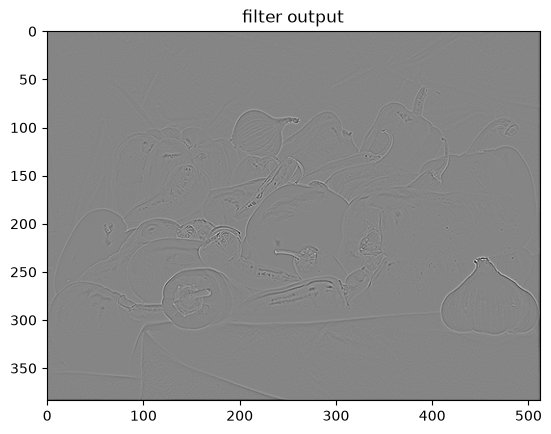

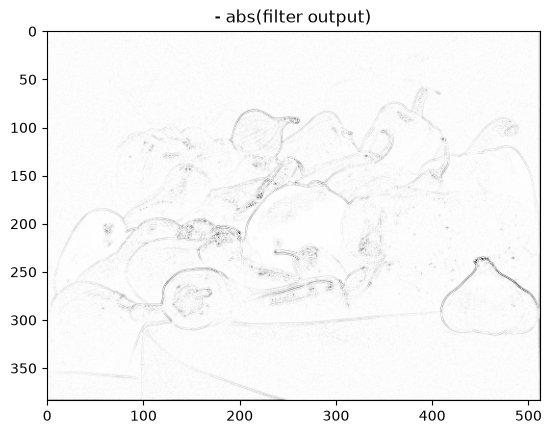

In [ ]:
w = torch.FloatTensor([[0, 1, 0], [1, -4, 1], [0, 1, 0]])
w = w.repeat(3, 1).reshape(1, 3, 3, 3)
conv_lap = torch.nn.Conv2d(3, 1, kernel_size=3, stride=1, padding=1, bias=False)
conv_lap.weight = torch.nn.Parameter(w)
y_lap = conv_lap(x)
print(x.size())
print(y_lap.size())

plt.figure()
vis_features(y_lap)
plt.title("filter output")

plt.figure()
vis_features(-torch.abs(y_lap))
plt.title("- abs(filter output)");

In [ ]:
w = torch.FloatTensor([[1], [0], [-1]]).repeat(1, 3, 1, 1)
w = torch.cat((w, -w), 0)

conv = torch.nn.Conv2d(3, 2, kernel_size=(3, 1), stride=1, padding=0, bias=False)
conv.weight = torch.nn.Parameter(w)
relu = torch.nn.ReLU()

y = conv(x)
z = relu(y)

plt.figure()
vis_features(y)
plt.figure()
vis_features(z)

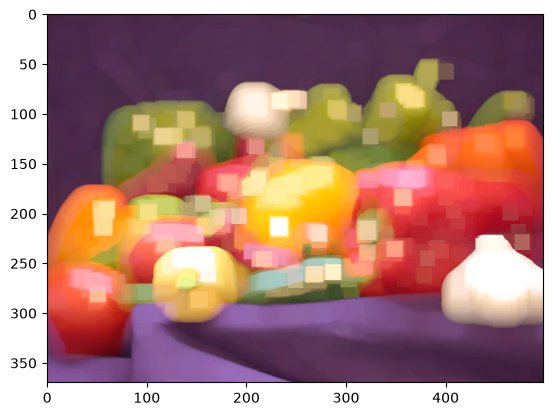

In [ ]:
mp = torch.nn.MaxPool2d(15, stride=1)
y = mp(x)
plt.imshow(y.squeeze().permute(1, 2, 0).numpy())
plt.gca().grid(False)

## CIFAR-10 classification

Both models receive the same normalized 32 × 32 RGB images and use SGD with cross-entropy. The baseline maps 3,072 pixel values directly to ten logits. The convolutional model uses two 5 × 5 convolutions with tanh and max pooling, followed by two linear layers. It has 258,058 trainable parameters.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(device)

In [ ]:
batch_size = 64  # input batch size for training
epochs = 10  # number of epochs to train
lr = 0.01  # learning rate

In [ ]:
data_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
trainset = datasets.CIFAR10(root="data", train=True, download=True, transform=data_transform)
testset = datasets.CIFAR10(root="data", train=False, download=True, transform=data_transform)

train_loader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=0)
test_loader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=0)

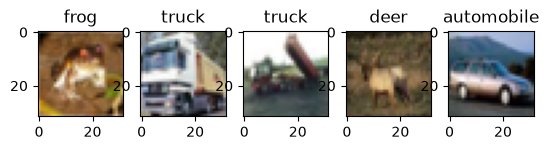

In [ ]:
fig, axes = plt.subplots(1, 5)

for i, ax in enumerate(axes):
    image, label = trainset[i]
    image = image * 0.5 + 0.5

    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title(trainset.classes[label])

In [ ]:
def train(epoch, network):
    network.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = network(data)
        loss = F.cross_entropy(output, target)
        loss.backward()
        optimizer.step()
        if batch_idx % 100 == 0:
            print(
                "Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}".format(
                    epoch,
                    batch_idx * len(data),
                    len(train_loader.dataset),
                    100.0 * batch_idx / len(train_loader),
                    loss.item(),
                )
            )


@torch.no_grad()
def test(network):
    network.eval()
    test_loss = 0
    correct = 0
    for data, target in test_loader:
        data, target = data.to(device), target.to(device)
        output = network(data)
        test_loss += F.cross_entropy(output, target, reduction="sum").item()  # sum up batch loss
        pred = output.data.max(1, keepdim=True)[1]  # get the index of the max log-probability
        correct += pred.eq(target.data.view_as(pred)).cpu().sum()

    test_loss /= len(test_loader.dataset)
    print(
        "\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n".format(
            test_loss, correct, len(test_loader.dataset), 100.0 * correct / len(test_loader.dataset)
        )
    )

In [ ]:
# Single layer network architecture


class Net(nn.Module):
    def __init__(self, num_inputs, num_outputs):
        super(Net, self).__init__()
        self.linear = nn.Linear(num_inputs, num_outputs)
        self.num_inputs = num_inputs

    def forward(self, input):
        input = input.view(-1, self.num_inputs)  # reshape input to batch x num_inputs
        output = self.linear(input)
        return output

In [ ]:
# Train
network = Net(3072, 10).to(device)
optimizer = optim.SGD(network.parameters(), lr=lr)
for epoch in range(1, epochs + 1):
    train(epoch, network)
    test(network)

Test set: Average loss: 1.7193, Accuracy: 4136/10000 (41%)

### Convolutional model

The first convolution produces 16 feature maps. The second produces 128. Pooling leaves a 128 × 5 × 5 tensor for the classifier. The final figure shows the sixteen learned first-layer filters.

In [ ]:
class ConvNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=5, stride=1, padding=0)
        self.conv2 = nn.Conv2d(16, 128, kernel_size=5, stride=1, padding=0)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(128 * 5 * 5, 64)
        self.fc2 = nn.Linear(64, 10)

    def forward(self, x):
        x = self.pool(torch.tanh(self.conv1(x)))
        x = self.pool(torch.tanh(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = torch.tanh(self.fc1(x))
        return self.fc2(x)

In [ ]:
# Train
network = ConvNet().to(device)
optimizer = optim.SGD(network.parameters(), lr=lr)
for epoch in range(1, 21):
    train(epoch, network)
    test(network)

Test set: Average loss: 1.0029, Accuracy: 6508/10000 (65%)

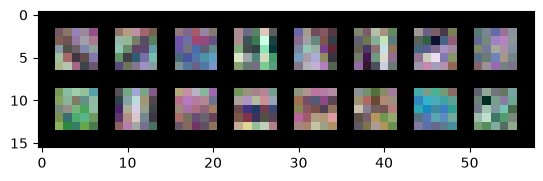

In [ ]:
weights = network.conv1.weight.detach().cpu()
grid = torchvision.utils.make_grid(weights, normalize=True)
plt.imshow(grid.permute(1, 2, 0))

The linear model classified 4,136 of 10,000 test images correctly after 10 epochs. The CNN reached 6,508 after 20. The training schedules differ, so the 23.72 percentage-point gap includes the effect of the longer run.